# 04. Final model: feature importance and variable removal experiment (report 3.2.5 / 3.2.6)
- 최종 모델: 규제한 Random Forest (03번 GridSearchCV 결과의 최적 파라미터)
- 데이터·분할·전처리는 02·03번과 동일: 학습 2024.03~2025.09 / 테스트 2025.10~2026.09
- 수업 노트북(ml2_EX "라벨인코딩", "원핫인코딩" 예제)의 흐름을 따름:
  feature_importances_ → permutation_importance → 변수 제거 전/후(개선전/개선후) 성능 비교 → joblib 모델 저장
- 실험 조합은 [CONFIG] 셀의 EXPERIMENTS만 고치면 됨
사전설치 : pip install pandas scikit-learn matplotlib joblib

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, auc, classification_report, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 노트북에는 __file__이 없으므로 실행 위치(code 폴더 또는 ML 폴더)로 기준 폴더를 정함
BASE_DIR = (Path.cwd().parent if Path.cwd().name == "code" else Path.cwd())
DATA_DIR = BASE_DIR / "데이터_csv"
MODEL_DIR = BASE_DIR / "model"
IMPORTANCE_PATH = DATA_DIR / "results_feature_importance.csv"
REMOVAL_PATH = DATA_DIR / "results_feature_removal.csv"

# 폰트지정 (원-핫 변수 이름에 행정동 한글이 들어가므로 필요)
plt.rcParams["font.family"] = "Malgun Gothic"
# 마이너스 부호 깨짐 지정
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# [CONFIG] features, split, final model, experiments
TARGET = "outflow"
CAT_FEATURES = ["dong", "month"]
PRICE_FEATURES = [
    "price_m2",
    "price_chg_1m", "price_chg_3m",
    "price_chg_1m_lag2", "price_chg_1m_lag3",
]
OTHER_FEATURES = [
    "trade_cnt", "trade_cnt_3m",
    "new_ratio", "build_year_avg",
    "pop_chg_rate_lag1", "population_lag1", "hh_size_lag1",
]
NUM_FEATURES = PRICE_FEATURES + OTHER_FEATURES
TRAIN_END = "2025-09"
THRESHOLD = 0.5
RANDOM_STATE = 42

# 03번 "Random Forest (regularized)"의 최적 파라미터
FINAL_PARAMS = {"n_estimators": 200, "max_depth": 2, "min_samples_split": 20, "min_samples_leaf": 5}

N_REPEATS = 10          # permutation_importance에서 변수를 섞는 횟수
PERM_SCORING = "roc_auc"

# 변수 제거 실험: 이름 → (범주형 변수, 수치형 변수)
# "Drop low importance"는 아래 permutation importance 결과로 자동 채움
EXPERIMENTS = {
    "Base (all features)": (CAT_FEATURES, NUM_FEATURES),
    "Without price features": (CAT_FEATURES, OTHER_FEATURES),
    "Price features only": (CAT_FEATURES, PRICE_FEATURES),
    "Add price_chg_12m": (CAT_FEATURES, NUM_FEATURES + ["price_chg_12m"]),
}

In [3]:
# Load data
raw = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_학습데이터셋.csv")


def split_data(cat_cols, num_cols):
    # 사용하는 변수에 결측이 있는 행만 제외하고 시간순으로 분할
    # (price_chg_12m을 넣으면 앞쪽 결측 때문에 학습 시작이 2024.12로 늦어짐)
    df = raw.dropna(subset=cat_cols + num_cols).reset_index(drop=True)
    train = df[df["ym"] <= TRAIN_END]
    test = df[df["ym"] > TRAIN_END]
    return train, test


def make_pipeline(cat_cols, num_cols):
    preprocessor = ColumnTransformer(transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    model = RandomForestClassifier(**FINAL_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
    return Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])


def evaluate(y_true, y_prob):
    # 02·03번과 동일한 지표 계산 (유출 = 1 이 양성)
    y_pred = (y_prob >= THRESHOLD).astype(int)
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": report["1"]["precision"],
        "Recall": report["1"]["recall"],
        "F1": report["1"]["f1-score"],
        "ROC-AUC": auc(fpr, tpr),
    }

In [4]:
# Train final model
train, test = split_data(CAT_FEATURES, NUM_FEATURES)
X_train, y_train = train[CAT_FEATURES + NUM_FEATURES], train[TARGET]
X_test, y_test = test[CAT_FEATURES + NUM_FEATURES], test[TARGET]

final_pipeline = make_pipeline(CAT_FEATURES, NUM_FEATURES)
final_pipeline.fit(X_train, y_train)
print(f"Train : {len(train)} rows ({train['ym'].min()} ~ {train['ym'].max()})")
print(f"Test  : {len(test)} rows ({test['ym'].min()} ~ {test['ym'].max()})")
print("Final model test performance:",
      {k: round(v, 4) for k, v in evaluate(y_test, final_pipeline.predict_proba(X_test)[:, 1]).items()})

Train : 228 rows (2024-03 ~ 2025-09)
Test  : 144 rows (2025-10 ~ 2026-09)
Final model test performance: {'Accuracy': 0.625, 'Precision': 0.6429, 'Recall': 0.7683, 'F1': 0.7, 'ROC-AUC': 0.6483}



Feature Importance (top 15):
pop_chg_rate_lag1    0.2669
hh_size_lag1         0.1197
population_lag1      0.0907
build_year_avg       0.0895
price_m2             0.0599
dong_망포2동            0.0588
trade_cnt            0.0530
trade_cnt_3m         0.0487
new_ratio            0.0422
dong_망포1동            0.0332
price_chg_1m         0.0271
price_chg_3m         0.0249
price_chg_1m_lag3    0.0243
price_chg_1m_lag2    0.0234
dong_매탄4동            0.0117


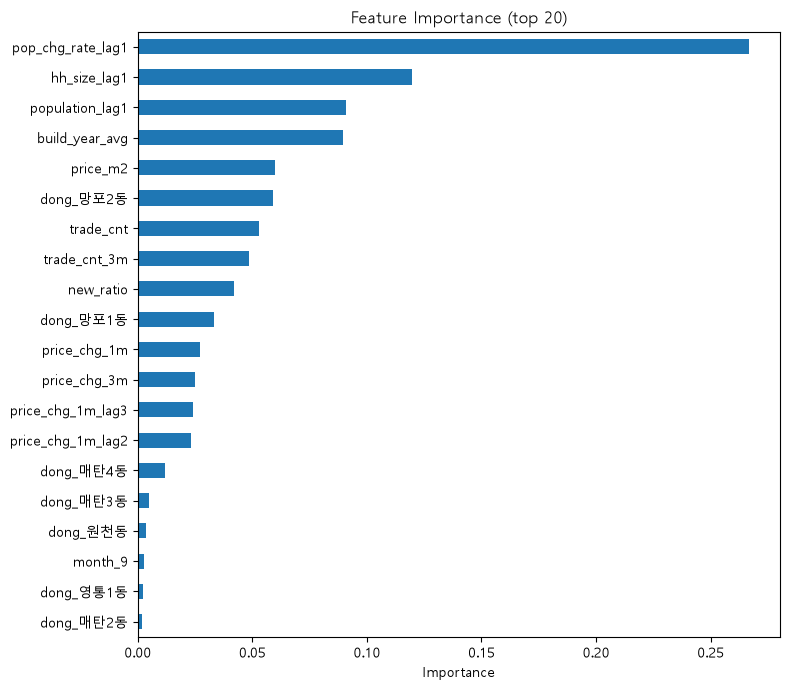

In [5]:
# Result 1: Feature Importance (report 3.2.5)
# 트리가 분할에 얼마나 자주·유용하게 쓴 변수인지 (원-핫 후 컬럼 단위: dong_매탄1동, month_7 등)
feature_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]          # "num__price_m2" → "price_m2"
importances = pd.Series(final_pipeline.named_steps["model"].feature_importances_, index=feature_names)

print("\nFeature Importance (top 15):")
print(importances.sort_values(ascending=False).head(15).round(4).to_string())

plt.figure(figsize=(8, 7))
importances.sort_values().tail(20).plot(kind="barh")
plt.title("Feature Importance (top 20)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


Permutation Importance (drop in test ROC-AUC):
          feature       group  importance_mean  importance_std
pop_chg_rate_lag1       other           0.0499          0.0295
   build_year_avg       other           0.0093          0.0069
     price_chg_3m       price           0.0059          0.0029
price_chg_1m_lag2       price           0.0047          0.0023
             dong region/time           0.0047          0.0081
        new_ratio       other           0.0043          0.0060
     hh_size_lag1       other           0.0040          0.0132
     trade_cnt_3m       other           0.0016          0.0056
        trade_cnt       other           0.0008          0.0058
         price_m2       price           0.0007          0.0042
price_chg_1m_lag3       price           0.0006          0.0030
  population_lag1       other           0.0000          0.0086
            month region/time          -0.0010          0.0014
     price_chg_1m       price          -0.0018          0.0025


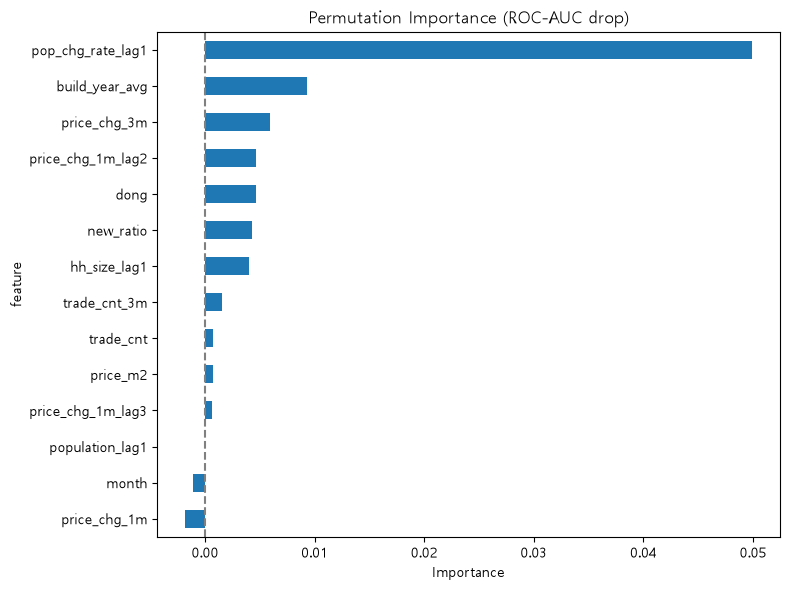

Saved: C:\Users\human-13\Desktop\ML\데이터_csv\results_feature_importance.csv


In [6]:
# Result 2: Permutation Importance (report 3.2.5)
# 테스트 데이터에서 변수 하나를 무작위로 섞었을 때 ROC-AUC가 얼마나 떨어지는지 측정
# Pipeline 전체에 적용하므로 dong, month는 원-핫 전 원래 변수 단위로 측정됨
# 0 이하 = 섞어도 성능이 그대로이거나 오히려 좋아짐 → 예측에 도움이 안 되는 변수
perm = permutation_importance(final_pipeline, X_test, y_test, n_repeats=N_REPEATS,
                              random_state=RANDOM_STATE, scoring=PERM_SCORING)
perm_importance = pd.DataFrame({
    "feature": X_test.columns,
    "group": ["price" if c in PRICE_FEATURES else "region/time" if c in CAT_FEATURES else "other"
              for c in X_test.columns],
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std,
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)

print("\nPermutation Importance (drop in test ROC-AUC):")
print(perm_importance.round(4).to_string(index=False))

plt.figure(figsize=(8, 6))
perm_importance.set_index("feature")["importance_mean"].sort_values().plot(kind="barh")
plt.axvline(0, color="gray", linestyle="--")
plt.title("Permutation Importance (ROC-AUC drop)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# 중요도 결과 저장 (permutation 기준 + 원-핫 컬럼별 feature_importances_)
perm_out = perm_importance.assign(method="permutation")
fi_out = importances.rename("importance_mean").rename_axis("feature").reset_index().assign(method="feature_importances_")
pd.concat([perm_out, fi_out], ignore_index=True).round(4).to_csv(IMPORTANCE_PATH, index=False, encoding="utf-8-sig")
print("Saved:", IMPORTANCE_PATH)

In [7]:
# Result 3: Variable removal experiment (report 3.2.6)
# permutation importance가 0 이하인 수치형 변수를 제거한 조합을 추가
# 주의: 같은 테스트 데이터로 고른 변수를 같은 테스트 데이터로 평가하므로 이 조합의 성능은 다소 낙관적임
low_importance = perm_importance.loc[(perm_importance["importance_mean"] <= 0)
                                     & perm_importance["feature"].isin(NUM_FEATURES), "feature"].tolist()
EXPERIMENTS["Drop low importance"] = (CAT_FEATURES, [c for c in NUM_FEATURES if c not in low_importance])
print("Low-importance features removed:", low_importance)

# 모든 조합에 같은 최종 모델 파라미터를 사용해 변수 차이만 비교
rows = []
for name, (cat_cols, num_cols) in EXPERIMENTS.items():
    tr_df, te_df = split_data(cat_cols, num_cols)
    pipeline = make_pipeline(cat_cols, num_cols)
    pipeline.fit(tr_df[cat_cols + num_cols], tr_df[TARGET])
    te = evaluate(te_df[TARGET], pipeline.predict_proba(te_df[cat_cols + num_cols])[:, 1])
    rows.append({
        "experiment": name,
        "n_features": len(cat_cols) + len(num_cols),
        "train_rows": len(tr_df), "train_start": tr_df["ym"].min(),
        "test_rows": len(te_df),
        **{f"test_{k}": v for k, v in te.items()},
        "removed_or_added": ", ".join(sorted(set(NUM_FEATURES) ^ set(num_cols))),
    })

removal = pd.DataFrame(rows)
base_auc = removal.loc[removal["experiment"] == "Base (all features)", "test_ROC-AUC"].iloc[0]
removal["diff_ROC-AUC_vs_base"] = removal["test_ROC-AUC"] - base_auc

pd.set_option("display.width", 250)
print(removal.drop(columns="removed_or_added").round(4).to_string(index=False))
removal.round(4).to_csv(REMOVAL_PATH, index=False, encoding="utf-8-sig")
print("Saved:", REMOVAL_PATH)

Low-importance features removed: ['price_chg_1m']


            experiment  n_features  train_rows train_start  test_rows  test_Accuracy  test_Precision  test_Recall  test_F1  test_ROC-AUC  diff_ROC-AUC_vs_base
   Base (all features)          14         228     2024-03        144         0.6250          0.6429       0.7683   0.7000        0.6483                0.0000
Without price features           9         240     2024-02        144         0.6181          0.6216       0.8415   0.7150        0.6393               -0.0090
   Price features only           7         228     2024-03        144         0.6528          0.6311       0.9390   0.7549        0.6273               -0.0210
     Add price_chg_12m          15         120     2024-12        144         0.6389          0.6316       0.8780   0.7347        0.6692                0.0208
   Drop low importance          13         228     2024-03        144         0.5972          0.6200       0.7561   0.6813        0.6456               -0.0028
Saved: C:\Users\human-13\Desktop\ML\데이터_csv\re

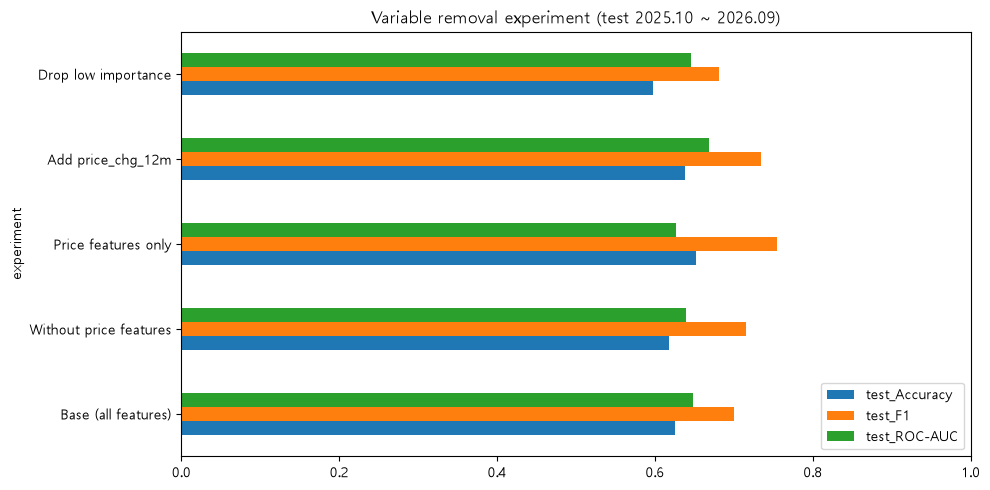

In [8]:
# Plot: removal experiment
ax = removal.set_index("experiment")[["test_Accuracy", "test_F1", "test_ROC-AUC"]].plot(kind="barh", figsize=(10, 5))
ax.set_xlim(0, 1)
ax.set_title("Variable removal experiment (test 2025.10 ~ 2026.09)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
# Save final model (Streamlit 등에서 불러와 사용)
# Pipeline 안에 전처리(스케일러·인코더)가 같이 들어 있어서 파일 하나만 저장하면 됨
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(final_pipeline, MODEL_DIR / "final_rf_pipeline.joblib")
joblib.dump({"cat_features": CAT_FEATURES, "num_features": NUM_FEATURES, "threshold": THRESHOLD,
             "params": FINAL_PARAMS}, MODEL_DIR / "features_meta.joblib")
print("Saved:", MODEL_DIR / "final_rf_pipeline.joblib")

Saved: C:\Users\human-13\Desktop\ML\model\final_rf_pipeline.joblib
